# Kuliah 6: Transformasi Z

Notebook ini memuat demo dan pemeriksaan numerik untuk pertemuan keenam. Urutannya mengikuti pendahuluan, sifat transformasi, fungsi sistem LTI, invers, dan transformasi satu sisi.

Jalankan sel persiapan dahulu, kemudian pilih **Run All** atau jalankan demo yang diperlukan. Semua fungsi pendukung disertakan di sini; Notebook tidak memerlukan impor dari berkas lokal.

Pustaka perhitungannya adalah NumPy dan Matplotlib dalam lingkungan Jupyter dengan kernel Python 3. Gambar ditampilkan inline melalui `plt.show()` dan tidak disimpan sebagai PNG terpisah.

Seluruh keluaran di bawah sudah dihitung dengan menjalankan kode. Pembahasan matematis lengkap dan empat belas contoh tersedia pada catatan `pertemuan-06.md`.

## Persiapan

Sel ini mendefinisikan fungsi transformasi berhingga, pembagian deret, integral invers, dan penggambaran ROC. Jalankan kembali jika kernel dimulai ulang.

In [1]:
%matplotlib inline
"""Fungsi pembelajaran transformasi Z; hanya membutuhkan NumPy dan Matplotlib."""
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

BIRU = '#176b9a'
JINGGA = '#cd641e'
plt.rcParams.update({'font.size': 10.5, 'axes.titlesize': 11,
                     'axes.grid': True, 'grid.alpha': 0.2})


def zt(x, n, z):
    """Jumlah transformasi sampel berhingga, dengan indeks eksplisit."""
    x = np.asarray(x, dtype=complex)
    n = np.asarray(n, dtype=int)
    z = np.asarray(z, dtype=complex)
    if x.ndim != 1 or x.shape != n.shape:
        raise ValueError('Nilai sampel dan indeks harus berupa vektor yang sama panjang.')
    return np.sum(x*z[..., None]**(-n), axis=-1)


def zplus(x, n, z):
    x, n = np.asarray(x), np.asarray(n)
    keep = n >= 0
    return zt(x[keep], n[keep], z)


def deret_rasional(b, a, jumlah):
    """Koefisien B(q)/A(q), q=z**(-1), koefisien diurutkan dari q**0."""
    b, a = np.asarray(b, complex), np.asarray(a, complex)
    if not len(a) or a[0] == 0:
        raise ValueError('Koefisien konstanta penyebut harus tidak nol.')
    c = np.zeros(jumlah, dtype=complex)
    for m in range(jumlah):
        rhs = b[m] if m < len(b) else 0
        for k in range(1, min(m, len(a)-1)+1):
            rhs -= a[k]*c[m-k]
        c[m] = rhs/a[0]
    return c


def invers_kontur(X, n, rho, M=1024):
    """Jumlah trapezoidal periodik pada lingkaran yang berada di ROC."""
    n = np.asarray(n, dtype=int)
    theta = 2*np.pi*np.arange(M)/M
    z = rho*np.exp(1j*theta)
    return rho**n*(np.exp(1j*np.outer(n, theta)) @ X(z))/M


def cocok(a, b, tol=1e-10):
    np.testing.assert_allclose(a, b, atol=tol, rtol=tol)


def stem(ax, n, x, warna=BIRU, label=None):
    marker, lines, baseline = ax.stem(n, np.real_if_close(x))
    plt.setp(marker, color=warna, markersize=5)
    plt.setp(lines, color=warna, linewidth=1.4)
    plt.setp(baseline, color='#777777', linewidth=0.6)
    if label:
        marker.set_label(label)
    ax.set_xlabel('Indeks n')
    ax.set_ylabel('Amplitudo')


def bidang_z(ax, poles=(), zeros=(), inner=0, outer=np.inf,
             limit=2.2, shade=True, title=''):
    """Gambar pole, zero, lingkaran satuan, dan ROC radial."""
    grid = np.linspace(-limit, limit, 301)
    xx, yy = np.meshgrid(grid, grid)
    radius = np.hypot(xx, yy)
    if shade:
        mask = ((radius > inner) & (radius < outer)).astype(float)
        ax.contourf(xx, yy, mask, levels=[0.5, 1.5], colors=['#b8dce9'], alpha=0.65)
    ax.add_patch(Circle((0, 0), 1, fill=False, linestyle='--', linewidth=1,
                        edgecolor='#888888', label='Lingkaran satuan'))
    for r in sorted(set([inner, outer])):
        if np.isfinite(r) and r > 0:
            ax.add_patch(Circle((0, 0), r, fill=False, linestyle=':',
                                edgecolor=BIRU, linewidth=1.5))
    if len(zeros):
        zz = np.asarray(zeros, complex)
        ax.scatter(zz.real, zz.imag, marker='o', facecolors='none',
                   edgecolors=JINGGA, s=75, linewidths=1.7, zorder=6, label='Zero')
    if len(poles):
        pp = np.asarray(poles, complex)
        ax.scatter(pp.real, pp.imag, marker='x', color='#b52d2d',
                   s=80, linewidths=2, zorder=7, label='Pole')
    ax.axhline(0, color='#777777', linewidth=0.6)
    ax.axvline(0, color='#777777', linewidth=0.6)
    ax.set(aspect='equal', xlim=(-limit, limit), ylim=(-limit, limit),
           xlabel='Bagian real z', ylabel='Bagian imajiner z', title=title)




def cetak(nama, data):
    print(nama, np.round(np.asarray(data), 8))


## 01. Eksponensial kanan dan kiri serta ROC

Demo mengikuti program `01_roc_eksponensial.py` dalam paket. Pemeriksaan `assert` akan memberi galat jika hasil numerik tidak sesuai dengan rumus yang diuji.

Transformasi kanan dan kiri sesuai pada titik di dalam ROC masing-masing.


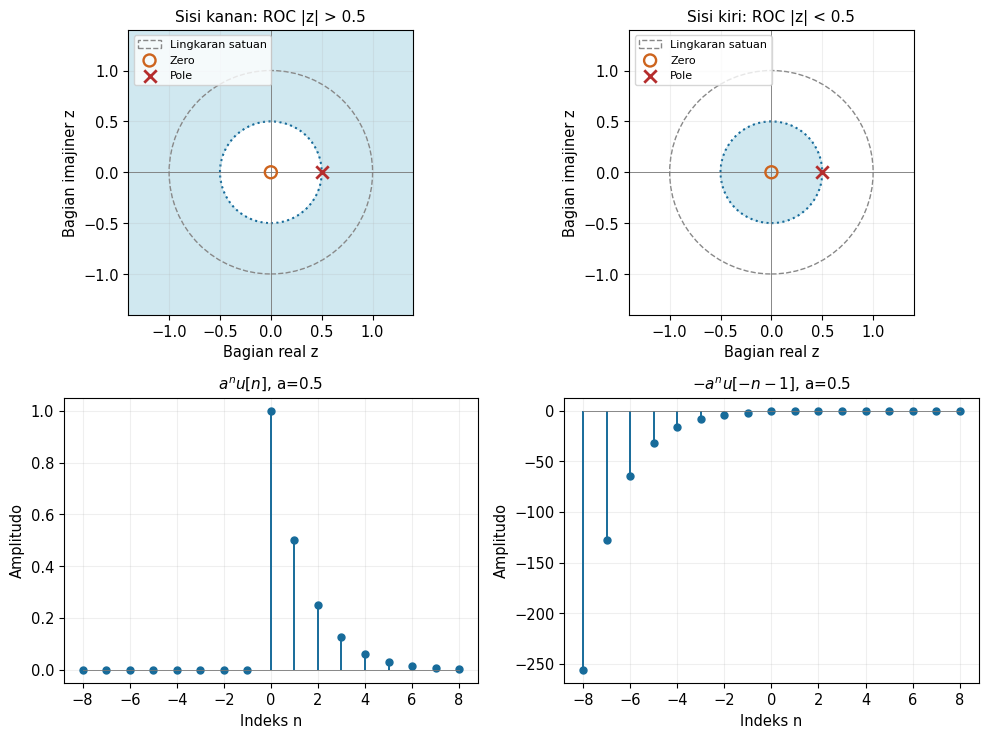

In [2]:
"""Eksponensial kanan dan kiri dengan ekspresi rasional sama."""

a = 0.5
fig, ax = plt.subplots(2, 2, figsize=(10, 7.5))
bidang_z(ax[0, 0], [a], [0], inner=a, limit=1.4,
          title='Sisi kanan: ROC |z| > 0.5')
bidang_z(ax[0, 1], [a], [0], outer=a, limit=1.4,
          title='Sisi kiri: ROC |z| < 0.5')
for p in ax[0]:
    p.legend(loc='upper left', fontsize=8)
n = np.arange(-8, 9)
right = np.where(n >= 0, a**n, 0)
left = np.where(n <= -1, -a**n, 0)
stem(ax[1, 0], n, right)
stem(ax[1, 1], n, left)
ax[1, 0].set_title(r'$a^n u[n]$, a=0.5')
ax[1, 1].set_title(r'$-a^n u[-n-1]$, a=0.5')
fig.tight_layout(); plt.show()
n = np.arange(160)
z = 1.2*np.exp(0.4j)
cocok(zt(a**n, n, z), z/(z-a))
n = -np.arange(1, 161)
z = 0.2*np.exp(0.4j)
cocok(zt(-a**n, n, z), z/(z-a))
print('Transformasi kanan dan kiri sesuai pada titik di dalam ROC masing-masing.')


## 02. Sinyal berhingga dan posisi indeks nol

Demo mengikuti program `02_sinyal_berhingga.py` dalam paket. Pemeriksaan `assert` akan memberi galat jika hasil numerik tidak sesuai dengan rumus yang diuji.

Polinomial dua sisi, pergeseran, dan pemotongan satu sisi diperiksa.


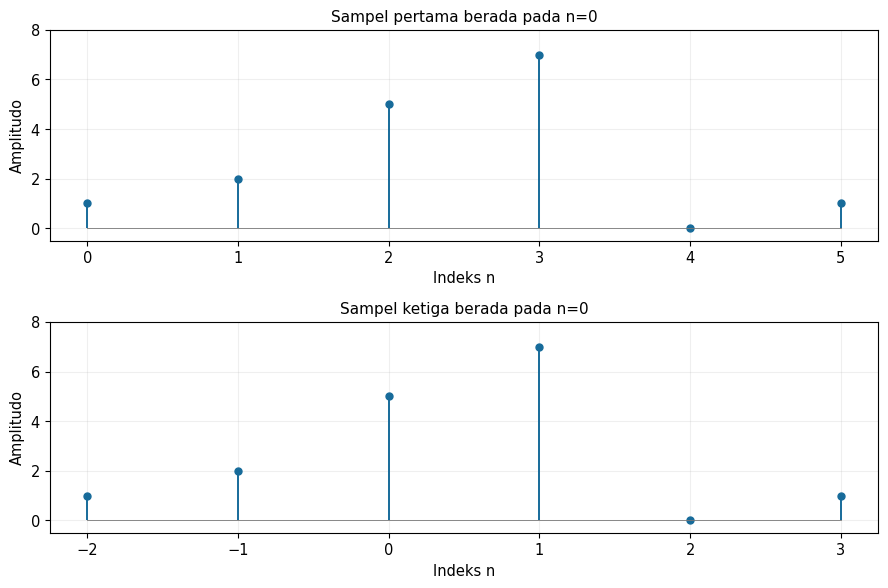

In [3]:
"""Peran posisi indeks nol pada transformasi dua sisi dan satu sisi."""

x = np.array([1, 2, 5, 7, 0, 1])
n1, n2 = np.arange(6), np.arange(-2, 4)
fig, ax = plt.subplots(2, 1, figsize=(9, 6))
stem(ax[0], n1, x)
stem(ax[1], n2, x)
ax[0].set_title('Sampel pertama berada pada n=0')
ax[1].set_title('Sampel ketiga berada pada n=0')
for p, n in zip(ax, [n1, n2]):
    p.set_xticks(n)
    p.set_ylim(-0.5, 8)
fig.tight_layout(); plt.show()
for z in [0.7+0.4j, 1.5-0.2j, -1+0.3j]:
    X1 = 1+2/z+5/z**2+7/z**3+1/z**5
    X2 = z*z+2*z+5+7/z+1/z**3
    cocok(zt(x, n1, z), X1)
    cocok(zt(x, n2, z), X2)
    cocok(X2, z*z*X1)
    cocok(zplus(x, n2, z), 5+7/z+1/z**3)
print('Polinomial dua sisi, pergeseran, dan pemotongan satu sisi diperiksa.')


## 03. Sifat transformasi dan irisan ROC

Demo mengikuti program `03_sifat.py` dalam paket. Pemeriksaan `assert` akan memberi galat jika hasil numerik tidak sesuai dengan rumus yang diuji.

Seluruh sifat dasar yang diuji sesuai, termasuk ROC cincin.


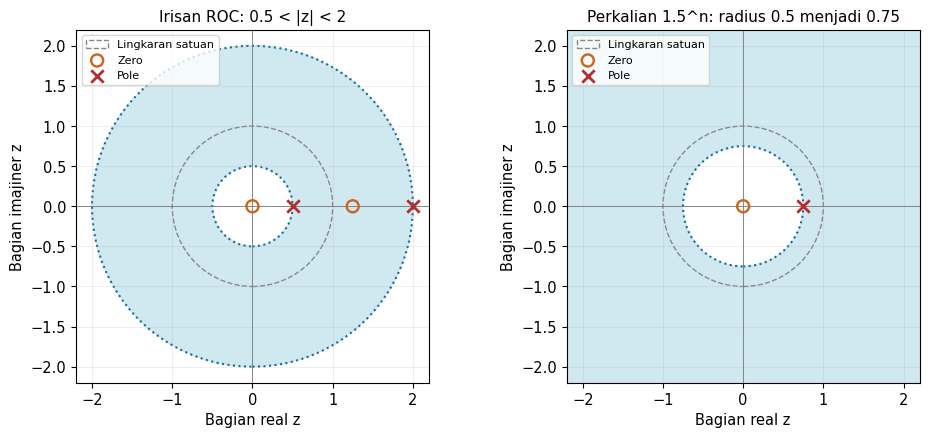

In [4]:
"""Linearitas, pergeseran, eksponensial, turunan, dan konvolusi."""

x = np.array([1, 2, -1, 3])
h = np.array([2, -1, 1])
nx, nh = np.arange(-1, 3), np.arange(3)
alpha = 1.2-0.3j
for z in [0.8+0.3j, 1.3+0.4j, 2-0.2j, -1.2+0.3j]:
    X = zt(x, nx, z)
    cocok(zt(x, nx+2, z), z**(-2)*X)
    cocok(zt(alpha**nx*x, nx, z), zt(x, nx, z/alpha))
    step = 1e-6
    derivative = (zt(x, nx, z+step)-zt(x, nx, z-step))/(2*step)
    cocok(zt(nx*x, nx, z), -z*derivative, 1e-6)
    ny = np.arange(nx[0]+nh[0], nx[-1]+nh[-1]+1)
    cocok(zt(np.convolve(x, h), ny, z), X*zt(h, nh, z))
    cocok(zt(2*x-0.3*x, nx, z), 1.7*X)
a, b = 0.5, 2.0
z = 1.2*np.exp(0.3j)
nr, nl = np.arange(160), -np.arange(1, 161)
cocok(zt(a**nr, nr, z)+zt(-b**nl, nl, z), z/(z-a)+z/(z-b))
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
bidang_z(ax[0], [a, b], [0, (a+b)/2], inner=a, outer=b,
          title='Irisan ROC: 0.5 < |z| < 2')
bidang_z(ax[1], [0.75], [0], inner=0.75,
          title='Perkalian 1.5^n: radius 0.5 menjadi 0.75')
for p in ax:
    p.legend(loc='upper left', fontsize=8)
fig.tight_layout(); plt.show()
print('Seluruh sifat dasar yang diuji sesuai, termasuk ROC cincin.')


## 04. Pole real, kompleks, dan berulang

Demo mengikuti program `04_pole_dan_sinyal.py` dalam paket. Pemeriksaan `assert` akan memberi galat jika hasil numerik tidak sesuai dengan rumus yang diuji.

Gambar pole real, kompleks-konjugat, dan berulang dibuat.


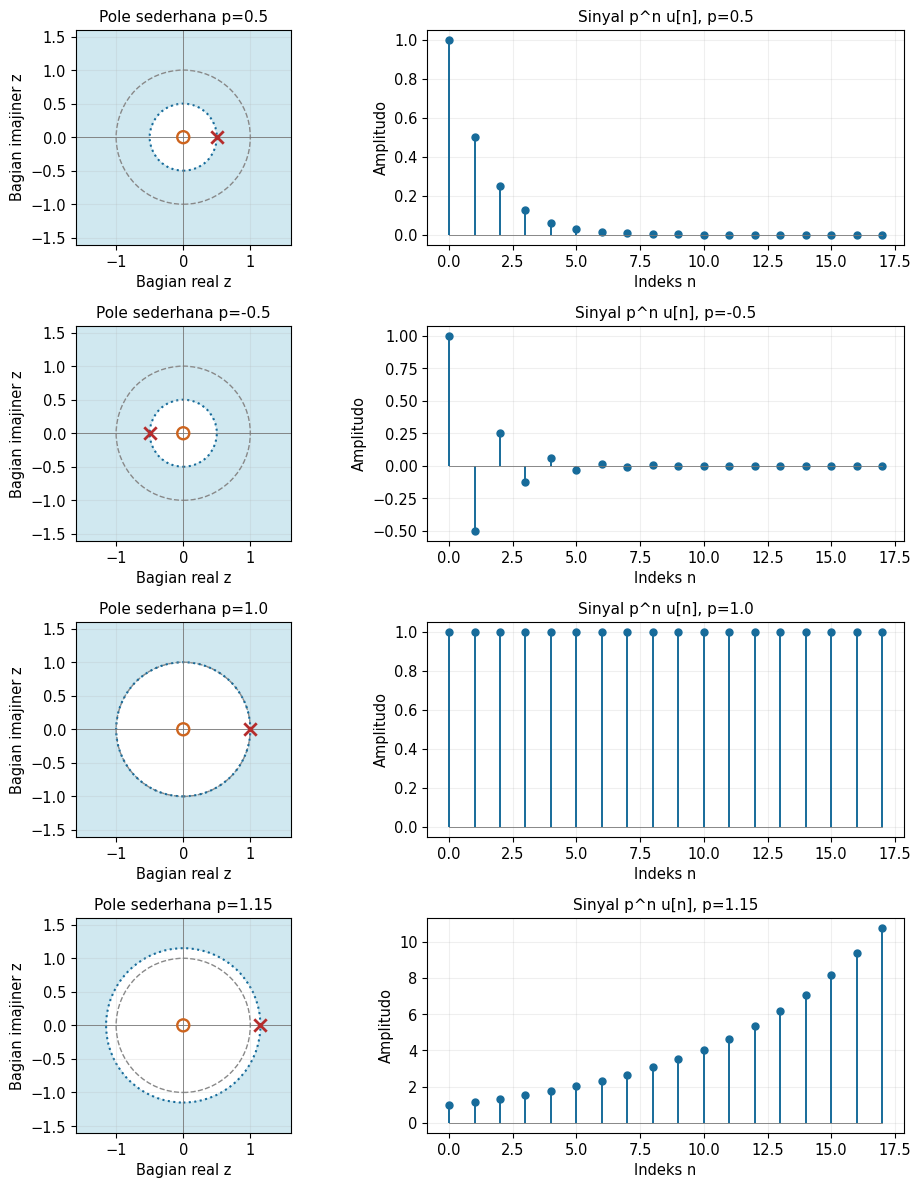

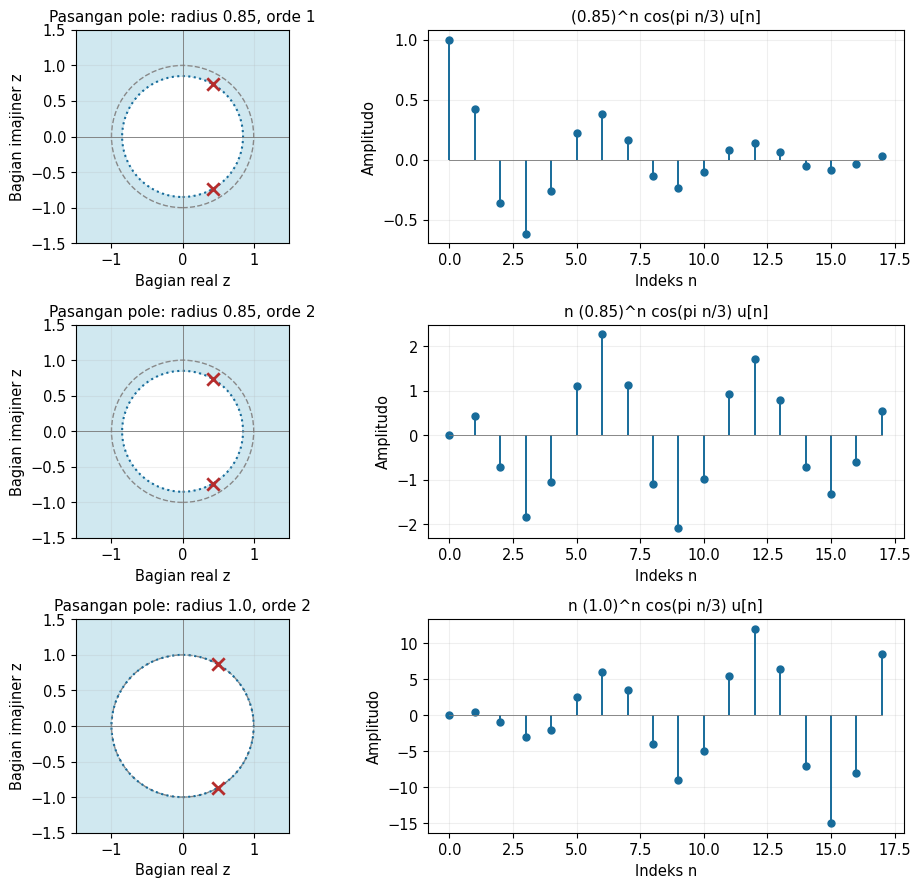

In [5]:
"""Hubungan radius, sudut, dan orde pole dengan sinyal kausal."""

n = np.arange(18)
fig, ax = plt.subplots(4, 2, figsize=(10, 12))
for row, p in enumerate([0.5, -0.5, 1.0, 1.15]):
    bidang_z(ax[row, 0], [p], [0], inner=abs(p), limit=1.6,
              title=f'Pole sederhana p={p}')
    stem(ax[row, 1], n, p**n)
    ax[row, 1].set_title(f'Sinyal p^n u[n], p={p}')
fig.tight_layout(); plt.show()
fig, ax = plt.subplots(3, 2, figsize=(10, 9))
theta = np.pi/3
for row, (r, repeated) in enumerate([(0.85, False), (0.85, True), (1.0, True)]):
    poles = [r*np.exp(1j*theta), r*np.exp(-1j*theta)]
    bidang_z(ax[row, 0], poles, inner=r, limit=1.5,
              title=f'Pasangan pole: radius {r}, orde {2 if repeated else 1}')
    values = r**n*np.cos(theta*n)
    if repeated:
        values = n*values
    stem(ax[row, 1], n, values)
    ax[row, 1].set_title(('n ' if repeated else '')+f'({r})^n cos(pi n/3) u[n]')
fig.tight_layout(); plt.show()
print('Gambar pole real, kompleks-konjugat, dan berulang dibuat.')


## 05. Fungsi sistem dan respons impuls

Demo mengikuti program `05_fungsi_sistem.py` dalam paket. Pemeriksaan `assert` akan memberi galat jika hasil numerik tidak sesuai dengan rumus yang diuji.

Respons impuls awal: [2.       1.       0.5      0.25     0.125    0.0625   0.03125  0.015625]
H(1)=4; H(-1)=4/3.


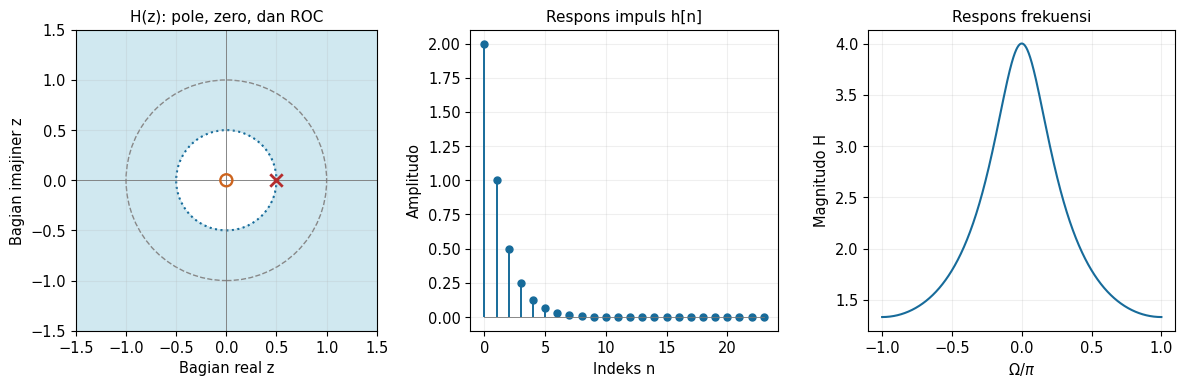

In [6]:
"""Respons impuls dari persamaan selisih dan respons frekuensi."""

n = np.arange(24)
h = np.empty(len(n))
prev = 0.0
for i in n:
    h[i] = 0.5*prev+2*(i == 0)
    prev = h[i]
cocok(h, 2*0.5**n)
w = np.linspace(-np.pi, np.pi, 1001)
H = 2/(1-0.5*np.exp(-1j*w))
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
bidang_z(ax[0], [0.5], [0], inner=0.5, limit=1.5, title='H(z): pole, zero, dan ROC')
stem(ax[1], n, h)
ax[1].set_title('Respons impuls h[n]')
ax[2].plot(w/np.pi, abs(H), color=BIRU)
ax[2].set(xlabel=r'$\Omega/\pi$', ylabel='Magnitudo H', title='Respons frekuensi')
fig.tight_layout(); plt.show()
cetak('Respons impuls awal:', h[:8])
cocok(2/(1-0.5), 4)
cocok(2/(1+0.5), 4/3)
print('H(1)=4; H(-1)=4/3.')


## 06. Invers melalui pembagian langsung

Demo mengikuti program `06_pembagian_langsung.py` dalam paket. Pemeriksaan `assert` akan memberi galat jika hasil numerik tidak sesuai dengan rumus yang diuji.

Koefisien sisi kanan: [1.       +0.j 1.5      +0.j 1.75     +0.j 1.875    +0.j 1.9375   +0.j
 1.96875  +0.j 1.984375 +0.j 1.9921875+0.j]
Koefisien pangkat positif z: [  0.+0.j   0.+0.j   2.+0.j   6.+0.j  14.+0.j  30.+0.j  62.+0.j 126.+0.j]


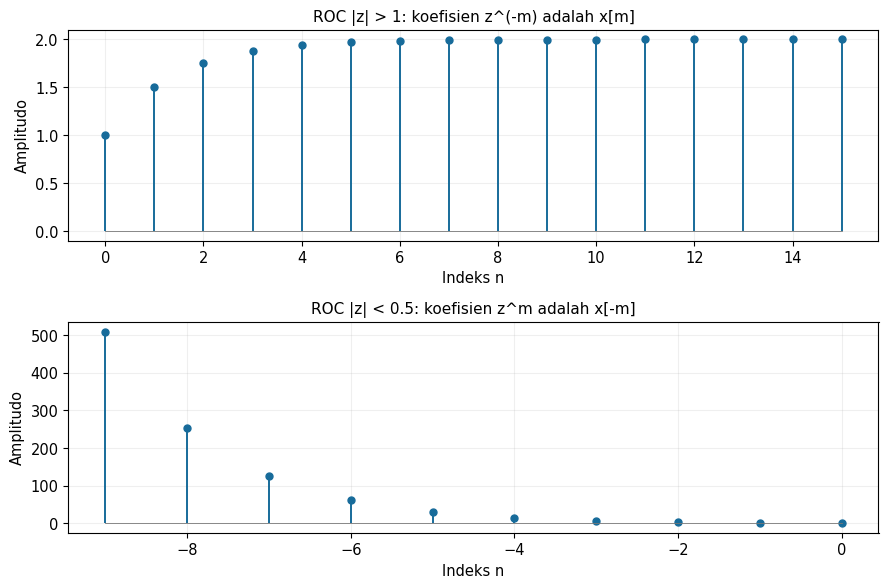

In [7]:
"""Koefisien ekspansi dalam pangkat negatif dan positif z."""

right = deret_rasional([1], [1, -1.5, 0.5], 16)
left = deret_rasional([0, 0, 1], [0.5, -1.5, 1], 10)
cocok(right[:5], [1, 1.5, 1.75, 1.875, 1.9375])
cocok(left[:7], [0, 0, 2, 6, 14, 30, 62])
fig, ax = plt.subplots(2, 1, figsize=(9, 6))
stem(ax[0], np.arange(len(right)), right.real)
ax[0].set_title('ROC |z| > 1: koefisien z^(-m) adalah x[m]')
stem(ax[1], -np.arange(len(left)), left.real)
ax[1].set_title('ROC |z| < 0.5: koefisien z^m adalah x[-m]')
fig.tight_layout(); plt.show()
cetak('Koefisien sisi kanan:', right[:8])
cetak('Koefisien pangkat positif z:', left[:8])


## 07. Pecahan parsial dan invers kausal

Demo mengikuti program `07_pecahan_parsial.py` dalam paket. Pemeriksaan `assert` akan memberi galat jika hasil numerik tidak sesuai dengan rumus yang diuji.

Koefisien sederhana: 2, -9, 8.
Koefisien pole berulang: A=3, B2=6, B1=-3.
Koefisien kompleks: -0.5, 0.4, 0.05+0.15j, 0.05-0.15j.
Sampel awal invers kompleks: [ 0.  0.  1.  0. -0.  2. -2.  2.]
Semua invers sesuai dengan koefisien pembagian fungsi rasional.


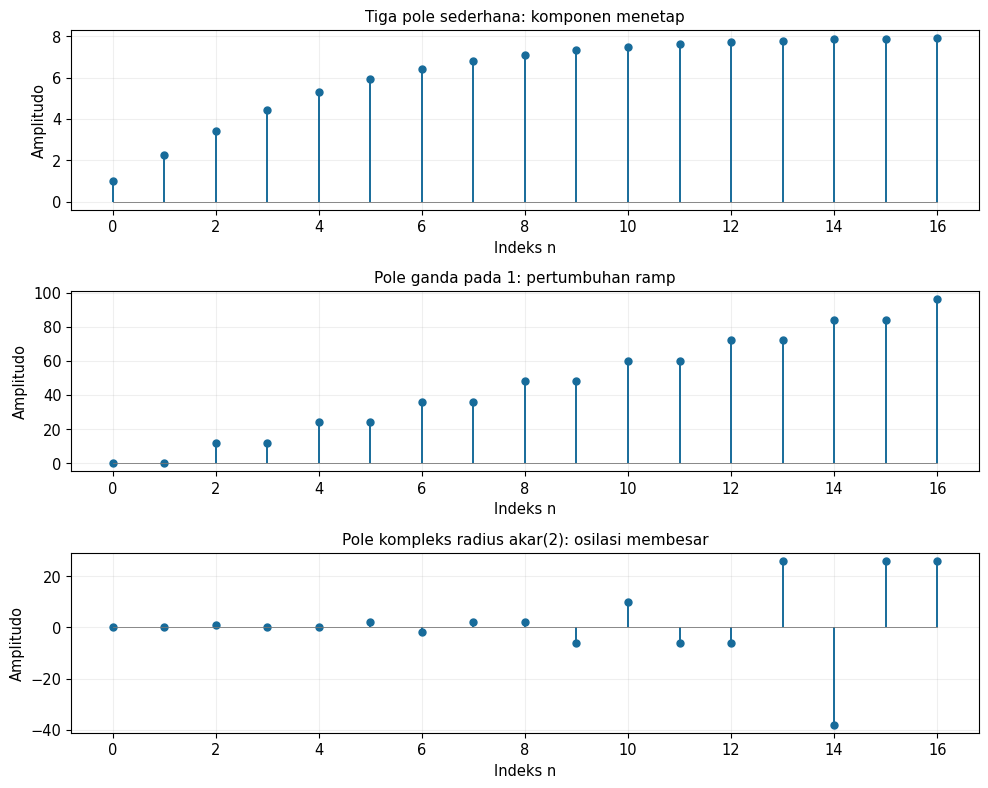

In [8]:
"""Tiga ekspansi dan invers kausalnya, termasuk pole kompleks."""

points = [2+0.4j, -2+0.7j, 1.8-0.3j]
for z in points:
    F1 = z*z/((z-0.5)*(z-0.75)*(z-1))
    cocok(F1, 2/(z-0.5)-9/(z-0.75)+8/(z-1))
    F2 = 12/((z+1)*(z-1)**2)
    cocok(F2, 3/(z+1)+6/(z-1)**2-3/(z-1))
    F3 = (z+1)/(z*(z-1)*(z*z+2*z+2))
    cocok(F3, -0.5/z+0.4/(z-1)+(0.05+0.15j)/(z+1-1j)
           +(0.05-0.15j)/(z+1+1j))
n = np.arange(17)
x1 = 2*0.5**n-9*0.75**n+8
x2 = 3*(-1.)**n+6*n-3
x3 = -0.5*(n == 0)+0.4+np.sqrt(2)**n*(
    0.1*np.cos(3*np.pi*n/4)-0.3*np.sin(3*np.pi*n/4))
cocok(x1, deret_rasional([1], [1, -2.25, 1.625, -0.375], len(n)))
cocok(x2, deret_rasional([0, 0, 12], [1, -1, -1, 1], len(n)))
cocok(x3, deret_rasional([0, 0, 1, 1], [1, 1, 0, -2], len(n)))
fig, ax = plt.subplots(3, 1, figsize=(10, 8))
for panel, x, title in zip(ax, [x1, x2, x3],
    ['Tiga pole sederhana: komponen menetap', 'Pole ganda pada 1: pertumbuhan ramp',
     'Pole kompleks radius akar(2): osilasi membesar']):
    stem(panel, n, x)
    panel.set_title(title)
fig.tight_layout(); plt.show()
print('Koefisien sederhana: 2, -9, 8.')
print('Koefisien pole berulang: A=3, B2=6, B1=-3.')
print('Koefisien kompleks: -0.5, 0.4, 0.05+0.15j, 0.05-0.15j.')
cetak('Sampel awal invers kompleks:', x3[:8])
print('Semua invers sesuai dengan koefisien pembagian fungsi rasional.')


## 08. Tiga ROC untuk satu fungsi rasional

Demo mengikuti program `08_tiga_roc.py` dalam paket. Pemeriksaan `assert` akan memberi galat jika hasil numerik tidak sesuai dengan rumus yang diuji.

Ketiga invers memberikan fungsi rasional sama di dalam ROC masing-masing.


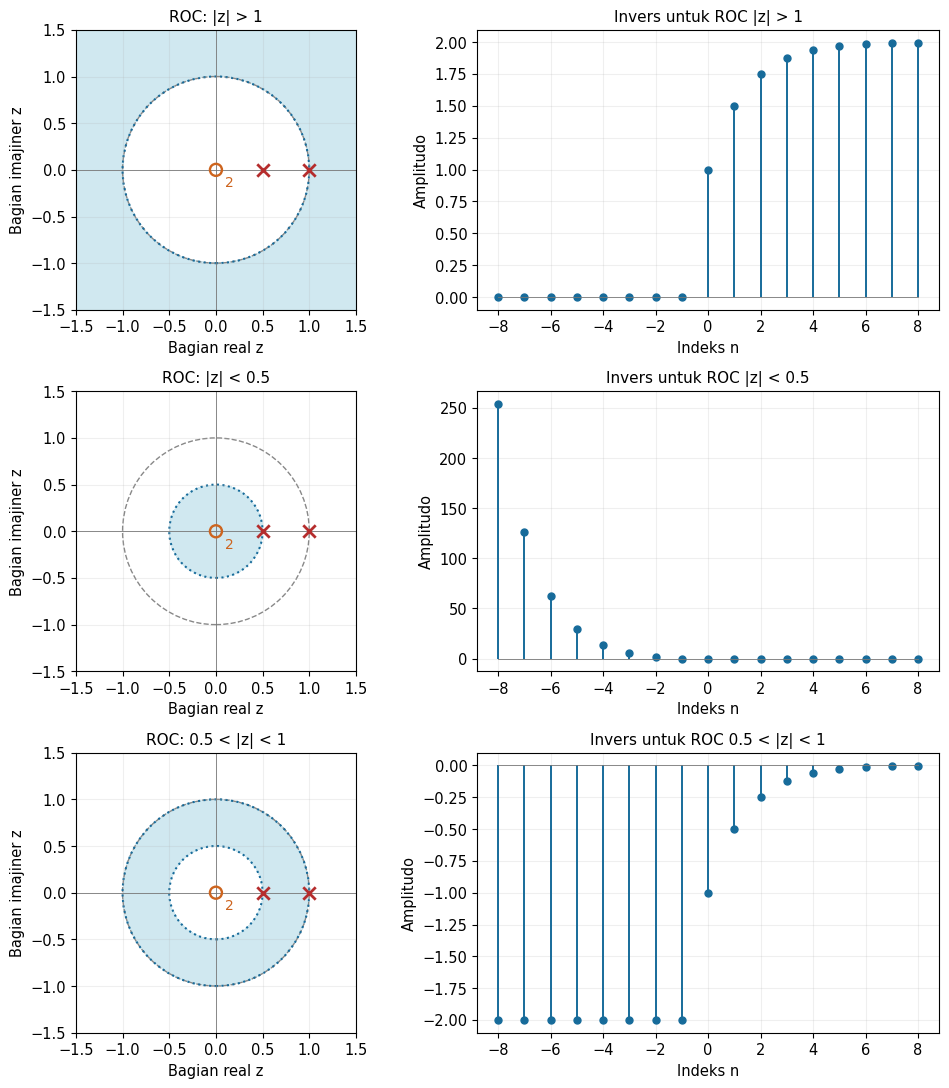

In [9]:
"""Satu ekspresi rasional dengan tiga ROC dan tiga sinyal berbeda."""

n = np.arange(-8, 9)
right = np.where(n >= 0, 2-0.5**n, 0)
left = np.where(n <= -1, -2+0.5**n, 0)
both = np.where(n <= -1, -2, -0.5**n)
fig, ax = plt.subplots(3, 2, figsize=(10, 11))
specs = [(1, np.inf, '|z| > 1'), (0, 0.5, '|z| < 0.5'), (0.5, 1, '0.5 < |z| < 1')]
for row, (values, (inner, outer, title)) in enumerate(zip([right, left, both], specs)):
    bidang_z(ax[row, 0], [0.5, 1], [0], inner=inner, outer=outer,
              limit=1.5, title='ROC: '+title)
    ax[row, 0].text(0.1, -0.18, '2', color=JINGGA, fontsize=10)
    stem(ax[row, 1], n, values)
    ax[row, 1].set_title('Invers untuk ROC '+title)
fig.tight_layout(); plt.show()
X = lambda z: 1/(1-1.5/z+0.5/z**2)
nr, nl = np.arange(200), -np.arange(1, 201)
z = 1.6*np.exp(0.2j)
cocok(zt(2-0.5**nr, nr, z), X(z))
z = 0.25*np.exp(0.2j)
cocok(zt(-2+0.5**nl, nl, z), X(z))
z = 0.75*np.exp(0.2j)
cocok(zt(np.full(len(nl), -2), nl, z)+zt(-0.5**nr, nr, z), X(z))
print('Ketiga invers memberikan fungsi rasional sama di dalam ROC masing-masing.')


## 09. Integral invers sepanjang kontur

Demo mengikuti program `09_integral_invers.py` dalam paket. Pemeriksaan `assert` akan memberi galat jika hasil numerik tidak sesuai dengan rumus yang diuji.

Galat maksimum integral invers: 5.551336578972477e-16
Tiga radius kontur di dalam ROC memberikan hasil yang sama.


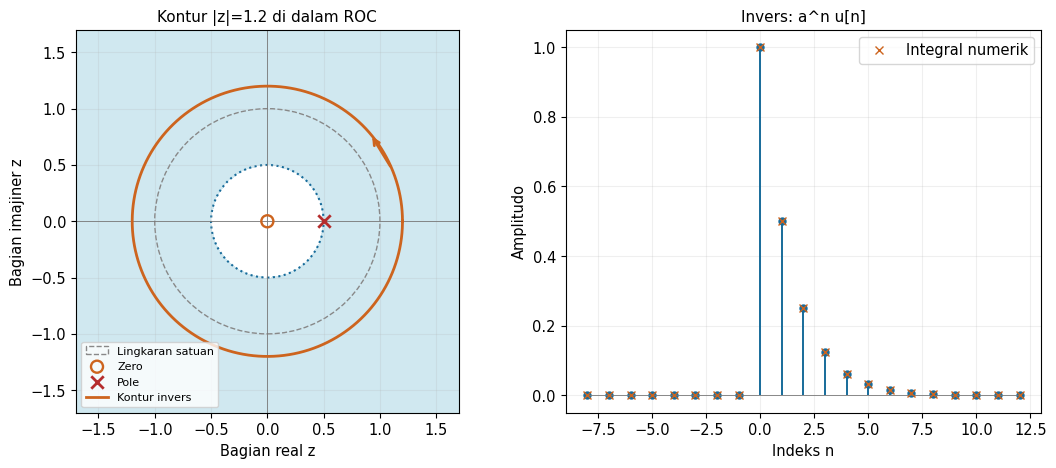

In [10]:
"""Integral kontur numerik dan pengambilan koefisien indeks negatif."""

a, rho = 0.5, 1.2
n = np.arange(-8, 13)
X = lambda z: z/(z-a)
back = invers_kontur(X, n, rho, 1024)
exact = np.where(n >= 0, a**n, 0)
cocok(back, exact)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.8))
bidang_z(ax[0], [a], [0], inner=a, limit=1.7, title='Kontur |z|=1.2 di dalam ROC')
t = np.linspace(0, 2*np.pi, 500)
ax[0].plot(rho*np.cos(t), rho*np.sin(t), color=JINGGA, linewidth=2, label='Kontur invers')
ax[0].annotate('', xy=(rho*np.cos(0.7), rho*np.sin(0.7)),
               xytext=(rho*np.cos(0.4), rho*np.sin(0.4)),
               arrowprops=dict(arrowstyle='->', color=JINGGA, linewidth=2))
ax[0].legend(loc='lower left', fontsize=8)
stem(ax[1], n, exact)
ax[1].plot(n, back.real, 'x', color=JINGGA, label='Integral numerik')
ax[1].set_title('Invers: a^n u[n]')
ax[1].legend()
fig.tight_layout(); plt.show()
print('Galat maksimum integral invers:', np.max(abs(back-exact)))
for rr in [0.7, 1.0, 1.5]:
    cocok(invers_kontur(X, n, rr, 1024), exact)
print('Tiga radius kontur di dalam ROC memberikan hasil yang sama.')


## 10. Transformasi satu sisi dan pergeseran

Demo mengikuti program `10_satu_sisi.py` dalam paket. Pemeriksaan `assert` akan memberi galat jika hasil numerik tidak sesuai dengan rumus yang diuji.

Suku batas kedua arah dan transformasi satu sisi sinyal berhingga sesuai.


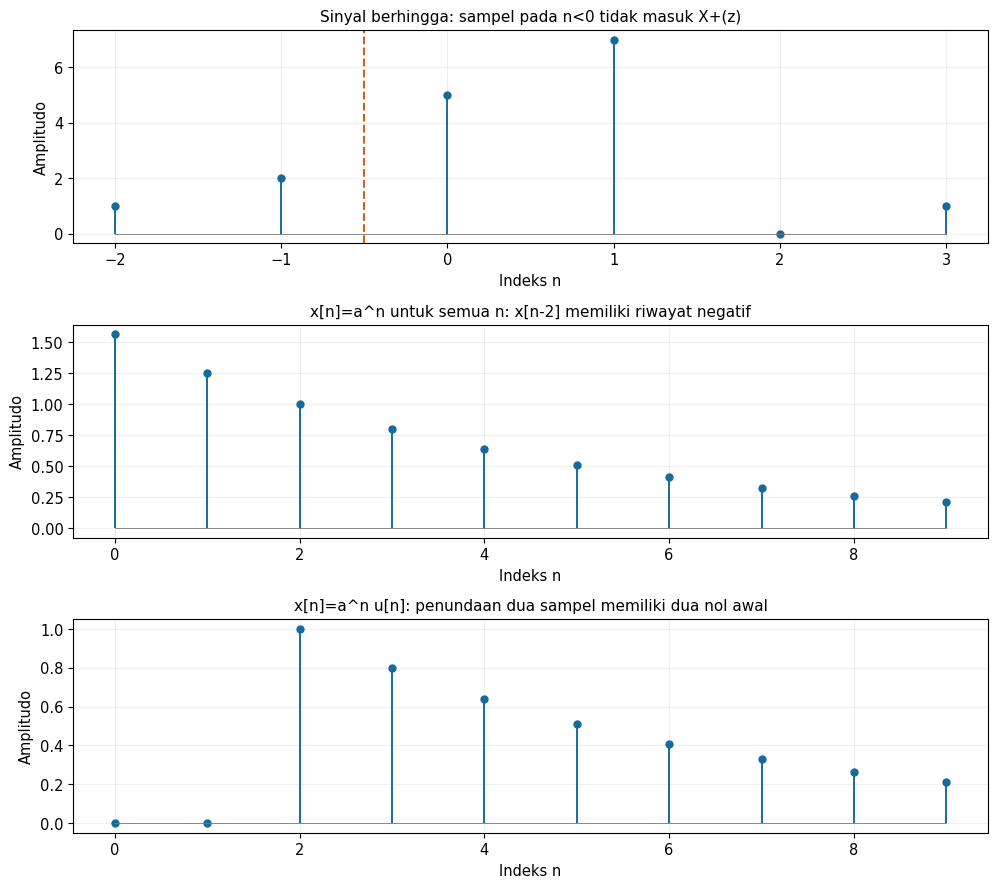

In [11]:
"""Pemotongan waktu negatif dan suku batas pada pergeseran satu sisi."""

x = np.array([1, 2, 5, 7, 0, 1])
n = np.arange(-2, 4)
fig, ax = plt.subplots(3, 1, figsize=(10, 9))
stem(ax[0], n, x)
ax[0].axvline(-0.5, linestyle='--', color=JINGGA)
ax[0].set_title('Sinyal berhingga: sampel pada n<0 tidak masuk X+(z)')
a = 0.8
nn = np.arange(10)
stem(ax[1], nn, a**(nn-2))
ax[1].set_title('x[n]=a^n untuk semua n: x[n-2] memiliki riwayat negatif')
shift_causal = np.where(nn >= 2, a**(nn-2), 0)
stem(ax[2], nn, shift_causal)
ax[2].set_title('x[n]=a^n u[n]: penundaan dua sampel memiliki dua nol awal')
fig.tight_layout(); plt.show()
nn = np.arange(180)
for z in [1.3+0.2j, 1.6-0.3j, -1.4+0.2j]:
    Xp = 1/(1-a/z)
    delay = z**(-2)*Xp+a**(-1)/z+a**(-2)
    advance = z*z*Xp-z*z-a*z
    cocok(delay, a**(-2)*Xp)
    cocok(advance, a*a*Xp)
    cocok(zt(a**(nn-2), nn, z), delay)
    cocok(zt(a**(nn+2), nn, z), advance)
    cocok(zplus(x, n, z), 5+7/z+1/z**3)
    cocok(zplus(x, n+2, z), z**(-2)*zplus(x, n, z)+2/z+1)
print('Suku batas kedua arah dan transformasi satu sisi sinyal berhingga sesuai.')


## 11. Pemeriksaan pasangan dan identitas tambahan

Demo mengikuti program `11_verifikasi.py` dalam paket. Pemeriksaan `assert` akan memberi galat jika hasil numerik tidak sesuai dengan rumus yang diuji.

In [12]:
"""Pemeriksaan tambahan seluruh pasangan dan identitas penting."""

a = 0.6
n = np.arange(200)
z = 1.4*np.exp(0.3j)
for values, expected in [
    (np.ones_like(n), z/(z-1)),
    (n, z/(z-1)**2),
    (n*n, z*(z+1)/(z-1)**3),
    (n**3, z*(z*z+4*z+1)/(z-1)**4),
    (a**n, z/(z-a)),
    (n*a**n, a*z/(z-a)**2),
    (n*n*a**n, a*z*(z+a)/(z-a)**3),
    (n**3*a**n, a*z*(z*z+4*a*z+a*a)/(z-a)**4),
    (np.sin(0.7*n), z*np.sin(0.7)/(z*z-2*z*np.cos(0.7)+1)),
    (np.cos(0.7*n), z*(z-np.cos(0.7))/(z*z-2*z*np.cos(0.7)+1)),
]:
    cocok(zt(values, n, z), expected)
nl = -np.arange(1, 201)
zl = 0.2*np.exp(0.4j)
cocok(zt(-nl*a**nl, nl, zl), a*zl/(zl-a)**2)
print('Seluruh pasangan pada tabel yang diuji sesuai.')
# Perkalian waktu melalui integral domain z untuk dua eksponensial kausal.
a, b = 0.5, 0.4
z = 1.2*np.exp(0.3j)
v = 0.7*np.exp(2j*np.pi*np.arange(2048)/2048)
product = np.mean((v/(v-a))*((z/v)/(z/v-b)))
cocok(product, z/(z-a*b))
print('Integral domain Z dari perkalian dua eksponensial sesuai.')
# Nilai akhir yang memenuhi syarat pole.
zz = 1+1e-7
cocok((1-1/zz)*zz/(zz-1), 1, 1e-7)
cocok((1-1/zz)*zz/(zz-0.5), 0, 1e-6)
# Respons persamaan selisih pada n>=0 dengan keadaan awal tak nol.
N = 30
y = np.empty(N)
prev = 3.0
for i in range(N):
    y[i] = 0.5*prev+2
    prev = y[i]
m = np.arange(N)
zero_state = 4*(1-0.5**(m+1))
initial_part = 1.5*0.5**m
cocok(y, zero_state+initial_part)
print('Respons keadaan nol dan kontribusi keadaan awal sesuai.')
print('SEMUA PEMERIKSAAN BERHASIL.')


Seluruh pasangan pada tabel yang diuji sesuai.
Integral domain Z dari perkalian dua eksponensial sesuai.
Respons keadaan nol dan kontribusi keadaan awal sesuai.
SEMUA PEMERIKSAAN BERHASIL.
